Q1:

Consider the Cats & Dogs example. Start initially with a training sample of 1000, a validation sample of 500, and a test sample of 500 (like in the text). Use any technique to reduce overfitting and improve performance in developing a network that you train from scratch. What performance did you achieve?

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Print Dataset found was used to confirm everything up to this point configured correctly.

In [ ]:
import os

zip_path = "/content/drive/MyDrive/BA64061_Assignment2/cats_vs_dogs_small.zip"

print("Dataset found:", os.path.exists(zip_path))

Dataset found: True


In [ ]:
import zipfile
from pathlib import Path

zip_path = "/content/drive/MyDrive/BA64061_Assignment2/cats_vs_dogs_small.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
  zip_ref.extractall("/content")

data_dir = Path("/content/cats_vs_dogs_small")

print("Dataset extracted:", data_dir.exists())

Dataset extracted: True


In the step above and the step below, the contents of the zip file are extracted and the Cats & Dogs images are prepared for use. The assignment requires small intial samples: 1,000 training images, 500 validation images, and 500 test images. Images are selected randomly and the original data is kept unchanged. the fixed random seed (123) allows the process to reproduce the same sample selection in subsequent runs.

In [ ]:
import random
import shutil
from pathlib import Path

random.seed(123)

source_dir = Path("/content/cats_vs_dogs_small")
output_dir = Path("/content/assignment2_question1")

sample_sizes = {
    "train": 500,
    "validation": 250,
    "test": 250
}

for subset, sample_size in sample_sizes.items():
  for category in ["cats", "dogs"]:

    source = source_dir / subset / category
    destination = output_dir / subset / category

    destination.mkdir(parents=True, exist_ok=True)

    #Select images randomly without replacement
    images = sorted(source.glob("*.jpg"))
    selected = random.sample(images, sample_size)

    #Copy selected images
    for image in selected:
      shutil.copy2(image, destination / image.name)

    print(f"{subset} - {category}: {len(selected)} images")

train - cats: 500 images
train - dogs: 500 images
validation - cats: 250 images
validation - dogs: 250 images
test - cats: 250 images
test - dogs: 250 images


Using the same image_dataset_from_directory() approach found in Chollet's second-edition Chapter 8 notebook, the keras package will load the images.

In [ ]:
import tensorflow as tf
from tensorflow import keras

base_dir = Path("/content/assignment2_question1")

train_dataset = keras.utils.image_dataset_from_directory(
    base_dir / "train",
    image_size=(180, 180),
    batch_size=32,
    label_mode="binary",
    shuffle=True,
    seed=123
)

validation_dataset = keras.utils.image_dataset_from_directory(
    base_dir / "validation",
    image_size=(180, 180),
    batch_size=32,
    label_mode="binary",
    shuffle=False
)

test_dataset = keras.utils.image_dataset_from_directory(
    base_dir / "test",
    image_size=(180, 180),
    batch_size=32,
    label_mode="binary",
    shuffle=False
)

Found 1000 files belonging to 2 classes.
Found 500 files belonging to 2 classes.
Found 500 files belonging to 2 classes.


The next section defines the data augmentation. Data augmentation randomly transforms training images to help the network recognize cats and dogs in different orientations and positions.

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2)
])

Build the CNN:

 This architecture uses five convolutional layers to progressively learn visual patterns, with max-pooling to reduce the dimensions of the feature maps. The final sigmoid layer produces a probability for binary classification.

In [ ]:
inputs = keras.Input(shape=(180, 180, 3))

x = data_augmentation(inputs)
x = layers.Rescaling(1./255)(x)

x = layers.Conv2D(32, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(64, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(128, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(256, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(256, 3, activation="relu")(x)

x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │        12,545 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 991,041 (3.78 MB)

 Trainable params: 991,041 (3.78 MB)

 Non-trainable params: 0 (0.00 B)

Compile the model:

Using binary cross-entropy, we're predicting one of two categories: cat or dog.

In [ ]:
model.compile(
    loss="binary_crossentropy",
    optimizer=keras.optimizers.RMSprop(learning_rate=1e-4),
    metrics=["accuracy"]
)

Train the CNN:

The model can train for up to 30 epochs, but early stopping will end training if validation loss stops improving for five consecutive epochs.

In [ ]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="assignment2_question1.keras",
        save_best_only=True,
        monitor="val_loss"
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )
]

history = model.fit(
    train_dataset,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks
)

Epoch 1/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 84ms/step - accuracy: 0.5000 - loss: 0.6944 - val_accuracy: 0.5020 - val_loss: 0.6917
Epoch 2/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - accuracy: 0.5140 - loss: 0.6926 - val_accuracy: 0.5240 - val_loss: 0.6911
Epoch 3/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - accuracy: 0.5270 - loss: 0.6911 - val_accuracy: 0.5480 - val_loss: 0.6892
Epoch 4/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 0.5530 - loss: 0.6891 - val_accuracy: 0.5100 - val_loss: 0.6868
Epoch 5/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - accuracy: 0.5470 - loss: 0.6871 - val_accuracy: 0.5100 - val_loss: 0.6943
Epoch 6/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 0.5400 - loss: 0.6860 - val_accuracy: 0.5520 - val_loss: 0.6808
Epoch 7/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - accuracy: 0.5620 - loss: 0.6817 - val_accuracy: 0.5360 - val_loss: 0.6882
Epoch 8/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - accuracy: 0.5610 - loss: 0.6781 - val_accuracy: 0.5860 - v

Evaluate the model:

This gives the first measured result.

In [ ]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.6860 - loss: 0.6196
Test Accuracy: 0.6860
Test Loss: 0.6196


Plot the learning curves:

Graphs will help identify whether the CNN is overfitting

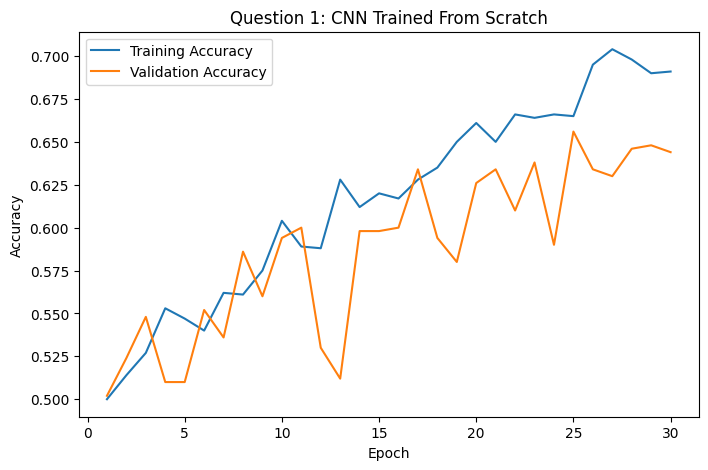

In [ ]:
import matplotlib.pyplot as plt

history_dict = history.history

epochs = range(1, len(history_dict["accuracy"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, history_dict["accuracy"], label="Training Accuracy")
plt.plot(epochs, history_dict["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Question 1: CNN Trained From Scratch")
plt.legend()
plt.show()

The graph demonstrates that the CNN is learning, but there is room to improve its performance.

**Instantiating a small convnet**

Q1:

Consider the Cats & Dogs example. Start initially with a training sample of 1000, a validation sample of 500, and a test sample of 500 (like in the text). Use any technique to reduce overfitting and improve performance in developing a network that you train from scratch. What performance did you achieve?

Results Interpretation:

Final training accuracy ~ 69%
Final validation accuracy ~ 64%

Based on the graph:
* The model is learning. Training accuracy rises from approximately 50% to 69%.
* Validation accuracy is improving, although it fluctuates considerably.
* Some overfitting is present. The gap between training and validation accuracy is approximately 5 percentage points at the final epoch.
* The model may benefit from additional training or optimization. Neither curve shows sustained plateau, although 30 epochs have already been completed.

These observations are consistent with the challenges of training a convolution network from scratch using a relatively small image dataset.

Importantly, the graph shows training and validation accuracy, not the final test accuracy.

In [ ]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.6860 - loss: 0.6196
Test Accuracy: 0.6860
Test Loss: 0.6196


In [ ]:
import pandas as pd

results = pd.DataFrame([{
    "Experiment": "Question 1",
    "Model": "CNN from scratch",
    "Training Images": 1000,
    "Validation Images": 500,
    "Test Images": 500,
    "Test Accuracy": test_accuracy,
    "Test Loss": test_loss
}])

results.to_csv(
    "/content/drive/MyDrive/BA64061_Assignment2/results.csv",
    index=False
)

results

,Experiment,Model,Training Images,Validation Images,Test Images,Test Accuracy,Test Loss
0,Question 1,CNN from scratch,1000,500,500,0.686,0.619551


Q2:

Increase your training sample size. You may pick any amount. Keep the validation and test samples the same as above. Optimize your network (again training from scratch). What performance did you achieve?

In [ ]:
train_dataset_q2 = keras.utils.image_dataset_from_directory(
    "/content/cats_vs_dogs_small/train",
    image_size=(180, 180),
    batch_size=32,
    label_mode="binary",
    shuffle=True,
    seed=123
)

Found 2000 files belonging to 2 classes.


Create a new CNN:

A new network needs to be initialized, rather than to continue with the training used above. Otherwise, this attempt would benefit from the earlier training and wouldn't be a fair comparison.

In [ ]:
# Recreate the CNN architecture for Question 2

inputs = keras.Input(shape=(180, 180, 3))

data_augmentation_q2 = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2)
])

x = data_augmentation_q2(inputs)
x = layers.Rescaling(1./255)(x)

x = layers.Conv2D(32, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(64, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(128, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(256, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(256, 3, activation="relu")(x)

x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model_q2 = keras.Model(inputs, outputs)

model_q2.compile(
    loss="binary_crossentropy",
    optimizer=keras.optimizers.RMSprop(learning_rate=1e-4),
    metrics=["accuracy"]
)

model_q2.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 7, 7, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │        12,545 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 991,041 (3.78 MB)

 Trainable params: 991,041 (3.78 MB)

 Non-trainable params: 0 (0.00 B)

Set up training

In [ ]:
callbacks_q2 = [
    keras.callbacks.ModelCheckpoint(
        filepath="assignment2_question2.keras",
        save_best_only=True,
        monitor="val_loss"
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )
]

history_q2 = model_q2.fit(
    train_dataset_q2,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks_q2
)

Epoch 1/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 66ms/step - accuracy: 0.4935 - loss: 0.6945 - val_accuracy: 0.5940 - val_loss: 0.6908
Epoch 2/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.5125 - loss: 0.6913 - val_accuracy: 0.5860 - val_loss: 0.6871
Epoch 3/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accuracy: 0.5595 - loss: 0.6856 - val_accuracy: 0.5780 - val_loss: 0.6783
Epoch 4/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.5575 - loss: 0.6814 - val_accuracy: 0.5780 - val_loss: 0.6715
Epoch 5/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.5830 - loss: 0.6751 - val_accuracy: 0.5940 - val_loss: 0.6644
Epoch 6/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.5830 - loss: 0.6704 - val_accuracy: 0.5780 - val_loss: 0.6606
Epoch 7/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.6195 - loss: 0.6646 - val_accuracy: 0.5840 - val_loss: 0.6718
Epoch 8/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.6035 - loss: 0.6597 - val_accuracy: 0.6040 - v

Evaluate the model

In [ ]:
test_loss_q2, test_accuracy_q2 = model_q2.evaluate(test_dataset)

print(f"Question 2 Test Accuracy: {test_accuracy_q2:.4f}")
print(f"Question 2 Test Loss: {test_loss_q2:.4f}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.7020 - loss: 0.5467
Question 2 Test Accuracy: 0.7020
Question 2 Test Loss: 0.5467


Compare the results from Q1 with Q2

In [ ]:
results = pd.DataFrame([
    {
        "Experiment": "Question 1",
        "Model": "CNN from scratch",
        "Training Images": 1000,
        "Test Accuracy": test_accuracy,
        "Test Loss": test_loss
    },
    {
        "Experiment": "Question 2",
        "Model": "CNN from scratch",
        "Training Images": 2000,
        "Test Accuracy": test_accuracy_q2,
        "Test Loss": test_loss_q2
    }
])

display(results)

results.to_csv(
    "/content/drive/MyDrive/BA64061_Assignment2/results.csv",
    index=False
)

,Experiment,Model,Training Images,Test Accuracy,Test Loss
0,Question 1,CNN from scratch,1000,0.686,0.619551
1,Question 2,CNN from scratch,2000,0.702,0.546730


Q2:

Increase your training sample size. You may pick any amount. Keep the validation and test samples the same as above. Optimize your network (again training from scratch). What performance did you achieve?

Results interpretation:

Test Accuracy 70.20%
Test Loss 0.5467 (reduced by 11.8% from the first model)

The improvement is modest but encouraging. The lower test loss also suggests that the second model assigned better probabilites to the correct classifications. It is still not conclusive that the improvement will consistently occur across repeated training runs.

Q3:

Now change your training sample so that you achieve better performance than those from Steps 1 and 2. This sample size may be larger, or smaller than those in the previous steps. The objective is to find the ideal training sample size to get best prediction results.

For the next attempt, I am trying 1,500 images with a slightly improved CNN architecture. This will help to examine whether a smaller, better-regularized model can outperform the 2,000 image experiment.

If both the sample size and network architecture are changed, the model will be testing a combined optimization strategy, not the effect of sample size alone.

In [ ]:
import random
import shutil
from pathlib import Path

random.seed(123)

source_dir = Path("/content/cats_vs_dogs_small/train")
output_dir = Path("/content/assignment2_question3/train")

for category in ["cats", "dogs"]:
    source = source_dir / category
    destination = output_dir / category

    destination.mkdir(parents=True, exist_ok=True)

    # Clear files from previous runs
    for old_file in destination.glob("*.jpg"):
        old_file.unlink()

    images = sorted(source.glob("*.jpg"))
    selected = random.sample(images, 750)

    for image in selected:
        shutil.copy2(image, destination / image.name)

train_dataset_q3 = keras.utils.image_dataset_from_directory(
    output_dir,
    image_size=(180, 180),
    batch_size=32,
    label_mode="binary",
    shuffle=True,
    seed=123
)

Found 1500 files belonging to 2 classes.


Build an improved CNN:

This version uses batch normalization and global average pooling to reduce the number of parameters in the classifier and dropout will be reduced from 0.5 to 0.4.

In [ ]:
inputs = keras.Input(shape=(180, 180, 3))

data_augmentation_q3 = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2)
])

x = data_augmentation_q3(inputs)
x = layers.Rescaling(1./255)(x)

for filters in [32, 64, 128, 256]:
    x = layers.Conv2D(
        filters, 3, padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(2)(x)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model_q3 = keras.Model(inputs, outputs)

model_q3.compile(
    loss="binary_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    metrics=["accuracy"]
)

model_q3.summary()

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_3 (Sequential)       │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 180, 180, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 180, 180, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 180, 180, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 90, 90, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 90, 90, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 90, 90, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 45, 45, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 45, 45, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 45, 45, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 22, 22, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 22, 22, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 22, 22, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 11, 11, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 390,113 (1.49 MB)

 Trainable params: 389,153 (1.48 MB)

 Non-trainable params: 960 (3.75 KB)

Train and Evaluate

In [ ]:
callbacks_q3 = [
    keras.callbacks.ModelCheckpoint(
        "assignment2_question3.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True
    )
]

history_q3 = model_q3.fit(
    train_dataset_q3,
    epochs=40,
    validation_data=validation_dataset,
    callbacks=callbacks_q3
)

Epoch 1/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 12s 133ms/step - accuracy: 0.5480 - loss: 0.7845 - val_accuracy: 0.5000 - val_loss: 0.7169
Epoch 2/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 102ms/step - accuracy: 0.5527 - loss: 0.7099 - val_accuracy: 0.5000 - val_loss: 0.7721
Epoch 3/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 102ms/step - accuracy: 0.5820 - loss: 0.7036 - val_accuracy: 0.4940 - val_loss: 0.7416
Epoch 4/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 103ms/step - accuracy: 0.5913 - loss: 0.6863 - val_accuracy: 0.5100 - val_loss: 0.7274
Epoch 5/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 102ms/step - accuracy: 0.6053 - loss: 0.6643 - val_accuracy: 0.5060 - val_loss: 0.7532
Epoch 6/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 102ms/step - accuracy: 0.6220 - loss: 0.6530 - val_accuracy: 0.5360 - val_loss: 0.7266
Epoch 7/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 103ms/step - accuracy: 0.6073 - loss: 0.6639 - val_accuracy: 0.5420 - val_loss: 0.7108
Epoch 8/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 99ms/step - accuracy: 0.6347 - loss: 0.6387 - val_accuracy: 0.

Evaluate on the unchanged test dataset

In [ ]:
test_loss_q3, test_accuracy_q3 = model_q3.evaluate(test_dataset)

print(f"Question 3 Test Accuracy: {test_accuracy_q3:.4f}")
print(f"Question 3 Test Loss: {test_loss_q3:.4f}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.6320 - loss: 0.6493
Question 3 Test Accuracy: 0.6320
Question 3 Test Loss: 0.6493


Q3:

Now change your training sample so that you achieve better performance than those from Steps 1 and 2. This sample size may be larger, or smaller than those in the previous steps. The objective is to find the ideal training sample size to get best prediction results.

Results Interpretation:

Test Accuracy 63.20%
Test Loss: 0.6493

Unfortunately, the modified CNN performed worse than both previous models. That's still a useful finding because it demonstrates that changing the architecture and training sample does not automatically improve performance.

It's difficult to determine which change caused the reduction in accuracy because several variables were changed simultaneously includeing the sample size for training, architecture, batch normalization, pooling, dropout, optimizer, and training settings.

Q3 Continued:

Rather than introduce another architecture, the following will return to the original CNN from the second question (Q2) and test it useing 1,500 training images. This will provide a more meaningful comparison of training sample sizes.

In [ ]:
# Build a fresh model using the Question 2 architecture
# with Question 3's 1,500 training images.

inputs = keras.Input(shape=(180, 180, 3))

augmentation_q3b = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2)
])

x = augmentation_q3b(inputs)
x = layers.Rescaling(1./255)(x)

x = layers.Conv2D(32, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(64, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(128, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(256, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(256, 3, activation="relu")(x)

x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model_q3b = keras.Model(inputs, outputs)

model_q3b.compile(
    loss="binary_crossentropy",
    optimizer=keras.optimizers.RMSprop(learning_rate=1e-4),
    metrics=["accuracy"]
)

In [ ]:
callbacks_q3b = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        "assignment2_question3b.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_q3b = model_q3b.fit(
    train_dataset_q3,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks_q3b
)

print(
    "Best Validation Accuracy:",
    max(history_q3b.history["val_accuracy"])
)
print(
    "Best Validation Loss:",
    min(history_q3b.history["val_loss"])
)

Epoch 1/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 79ms/step - accuracy: 0.5060 - loss: 0.6938 - val_accuracy: 0.5000 - val_loss: 0.6918
Epoch 2/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.5080 - loss: 0.6920 - val_accuracy: 0.5000 - val_loss: 0.6907
Epoch 3/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.5127 - loss: 0.6908 - val_accuracy: 0.5140 - val_loss: 0.6872
Epoch 4/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.5440 - loss: 0.6874 - val_accuracy: 0.5140 - val_loss: 0.6842
Epoch 5/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.5527 - loss: 0.6811 - val_accuracy: 0.5760 - val_loss: 0.6759
Epoch 6/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.5693 - loss: 0.6761 - val_accuracy: 0.6000 - val_loss: 0.6675
Epoch 7/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.6027 - loss: 0.6714 - val_accuracy: 0.5580 - val_loss: 0.6776
Epoch 8/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.5993 - loss: 0.6645 - val_accuracy: 0.6060 - v

Before deciding to optimize the CNN further, the following will test the best validation results

In [ ]:
import numpy as np

best_epoch = np.argmin(history_q3b.history["val_loss"])

print("Best Epoch:", best_epoch + 1)
print(
    "Validation Accuracy at Best Epoch:",
    f"{history_q3b.history['val_accuracy'][best_epoch]:.4f}"
)
print(
    "Validation Loss at Best Epoch:",
    f"{history_q3b.history['val_loss'][best_epoch]:.4f}"
)

Best Epoch: 28
Validation Accuracy at Best Epoch: 0.6800
Validation Loss at Best Epoch: 0.5563


Compare these validation results

In [ ]:
import numpy as np
import pandas as pd

histories = {
    "Q1 - 1000 Images": history,
    "Q2 - 2000 Images": history_q2,
    "Q3 - 1500 Images": history_q3b
}

comparison = []

for name, h in histories.items():
    best_epoch = np.argmin(h.history["val_loss"])

    comparison.append({
        "Experiment": name,
        "Best Epoch": best_epoch + 1,
        "Validation Accuracy": round(
            h.history["val_accuracy"][best_epoch], 4
        ),
        "Validation Loss": round(
            h.history["val_loss"][best_epoch], 4
        )
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df)

,Experiment,Best Epoch,Validation Accuracy,Validation Loss
0,Q1 - 1000 Images,28,0.646,0.6236
1,Q2 - 2000 Images,30,0.698,0.5509
2,Q3 - 1500 Images,28,0.680,0.5563


These results provide a clear picture of how training sample size affects CNN performance. The 2,000 image model is currently the best performing model trained from scratch, with the highest validation accuracy of ~69% and least validation loss of 0.5509.

In [ ]:
comparison_df.to_csv(
    "/content/drive/MyDrive/BA64061_Assignment2/validation_comparison.csv",
    index=False
)

Below were my attempts to download the larger dataset from Kaggle. It seems that obtaining permission either takes days or they are no longer giving permission to use this old data set.

In [ ]:
!pip -q install kaggle

In [ ]:
!pip -q install kagglehub

In [ ]:
import kagglehub

kagglehub.login()

Kaggle credentials set.
Kaggle credentials successfully validated.


In [ ]:
import kagglehub

dataset_path = kagglehub.competition_download("dogs-vs-cats")

print("Dataset downloaded to:", dataset_path)

KaggleApiHTTPError: 403 Client Error.

You don't have permission to access resource at URL: https://kaggle.com/competitions/dogs-vs-cats
Please make sure you are authenticated and have accepted the competition rules which can be found at this location: https://kaggle.com/competitions/dogs-vs-cats/rules

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('dogs-vs-cats')

print("Path to competition files:", path)

KaggleApiHTTPError: 403 Client Error.

You don't have permission to access resource at URL: https://kaggle.com/competitions/dogs-vs-cats
Please make sure you are authenticated and have accepted the competition rules which can be found at this location: https://kaggle.com/competitions/dogs-vs-cats/rules

Microsoft provides a large Cats and Dogs dataset, and the official Keras tutorial uses it for image classification. https://keras.io/examples/vision/image_classification_from_scratch/

In [ ]:
import tensorflow as tf

large_dataset_zip = tf.keras.utils.get_file(
    fname="kagglecatsanddogs_5340.zip",
    origin=(
        "https://download.microsoft.com/download/3/E/1/"
        "3E1C3F21-ECDB-4869-8368-6DEBA77B919F/"
        "kagglecatsanddogs_5340.zip"
    ),
    cache_dir="/content",
    cache_subdir="large_cats_dogs"
)

print("Downloaded to:", large_dataset_zip)

824887076/824887076 ━━━━━━━━━━━━━━━━━━━━ 11s 0us/step
Downloaded to: /content/large_cats_dogs/kagglecatsanddogs_5340.zip


Verify the download

In [ ]:
from pathlib import Path

zip_file = Path(large_dataset_zip)

print("Download successful:", zip_file.exists())
print(
    "File size (MB):",
    round(zip_file.stat().st_size / (1024**2), 2)
)

Download successful: True
File size (MB): 786.67


Extract the larger dataset

In [ ]:
import zipfile
from pathlib import Path

large_data_dir = Path("/content/cats_dogs_large")

large_data_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(large_dataset_zip, "r") as zip_ref:
    zip_ref.extractall(large_data_dir)

print("Extraction complete!")

for folder in large_data_dir.iterdir():
    print(folder.name)

Extraction complete!
PetImages
readme[1].txt
CDLA-Permissive-2.0.pdf


Identify and inspect the images

In [ ]:
from pathlib import Path

cats_dir = large_data_dir / "PetImages" / "Cat"
dogs_dir = large_data_dir / "PetImages" / "Dog"

print("Cat folder exists:", cats_dir.exists())
print("Dog folder exists:", dogs_dir.exists())

print("Cat images:", len(list(cats_dir.glob("*.jpg"))))
print("Dog images:", len(list(dogs_dir.glob("*.jpg"))))

Cat folder exists: True
Dog folder exists: True
Cat images: 12500
Dog images: 12500


Check for overlap with the original dataset

In [ ]:
import hashlib

def file_hash(filepath):
    sha256 = hashlib.sha256()
    with open(filepath, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)
    return sha256.hexdigest()

# Existing validation and test images
existing_eval_dirs = [
    Path("/content/assignment2_question1/validation"),
    Path("/content/assignment2_question1/test")
]

evaluation_hashes = set()

for directory in existing_eval_dirs:
    for image_path in directory.rglob("*.jpg"):
        evaluation_hashes.add(file_hash(image_path))

print("Unique evaluation image hashes:", len(evaluation_hashes))

# Check candidate images from the larger dataset
large_images = (
    list(cats_dir.glob("*.jpg")) +
    list(dogs_dir.glob("*.jpg"))
)

overlap_count = 0

for image_path in large_images:
    if file_hash(image_path) in evaluation_hashes:
        overlap_count += 1

print("Exact duplicate images found:", overlap_count)

Unique evaluation image hashes: 1000
Exact duplicate images found: 1003


Prepare the 10,000 image training dataset

This code will:
1. Exclude images matching our existing validation and test files.
2. Exclude matching original Kaggle image identifiers where identifiable.
3. Skip images that cannot be decoded.
4. Randomly select 5,000 cats and 5,000 dogs.
5. Create a new training directory without modifying the original datasets.

In [ ]:
import random
import shutil
import hashlib
from pathlib import Path
from PIL import Image, ImageOps

random.seed(123)

output_dir_q3large = Path("/content/assignment2_question3_large/train")

# Existing validation and test images
evaluation_dirs = [
    Path("/content/assignment2_question1/validation"),
    Path("/content/assignment2_question1/test")
]

# Collect image hashes and filenames
evaluation_hashes = set()
evaluation_names = set()

for directory in evaluation_dirs:
    for image_path in directory.rglob("*.jpg"):
        evaluation_hashes.add(file_hash(image_path))
        evaluation_names.add(image_path.name.lower())

# Check whether an image can be decoded
def valid_image(filepath):
    try:
        with Image.open(filepath) as img:
            img.verify()
        with Image.open(filepath) as img:
            ImageOps.exif_transpose(img).convert("RGB").load()
        return True
    except Exception:
        return False

for category, source_dir in [
    ("cats", cats_dir),
    ("dogs", dogs_dir)
]:
    destination = output_dir_q3large / category
    destination.mkdir(parents=True, exist_ok=True)

    # Clear previous samples if rerunning
    for old_file in destination.iterdir():
        if old_file.is_file():
            old_file.unlink()

    eligible = []
    excluded_hash = 0
    excluded_name = 0
    invalid = 0

    for image_path in sorted(source_dir.glob("*.jpg")):

        # Exclude exact duplicates
        if file_hash(image_path) in evaluation_hashes:
            excluded_hash += 1
            continue

        # Exclude matching filenames where available
        if image_path.name.lower() in evaluation_names:
            excluded_name += 1
            continue

        # Exclude unreadable images
        if not valid_image(image_path):
            invalid += 1
            continue

        eligible.append(image_path)

    print(f"\n{category.upper()}")
    print("Excluded by hash:", excluded_hash)
    print("Excluded by name:", excluded_name)
    print("Invalid images:", invalid)
    print("Eligible images:", len(eligible))

    if len(eligible) < 5000:
        raise ValueError(
            f"Not enough eligible {category} images."
        )

    selected = random.sample(eligible, 5000)

    for image_path in selected:
        shutil.copy2(
            image_path,
            destination / image_path.name
        )

    print("Selected:", len(selected))


CATS
Excluded by hash: 501
Excluded by name: 237
Invalid images: 1
Eligible images: 11761
Selected: 5000


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))



DOGS
Excluded by hash: 502
Excluded by name: 237
Invalid images: 1
Eligible images: 11760
Selected: 5000


Load the larger training sample

In [ ]:
train_dataset_q3large = keras.utils.image_dataset_from_directory(
    "/content/assignment2_question3_large/train",
    image_size=(180, 180),
    batch_size=32,
    label_mode="binary",
    shuffle=True,
    seed=123
)

Found 10000 files belonging to 2 classes.


Verify the final sample

In [ ]:
print("Training batches:", len(train_dataset_q3large))
print("Validation batches:", len(validation_dataset))
print("Test batches:", len(test_dataset))

Training batches: 313
Validation batches: 16
Test batches: 16


Build the CNN for the larger dataset

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set random seed for reproducibility
keras.utils.set_random_seed(123)

# Data augmentation
augmentation_large = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2)
])

# Build CNN from scratch
inputs = keras.Input(shape=(180, 180, 3))

x = augmentation_large(inputs)
x = layers.Rescaling(1./255)(x)

x = layers.Conv2D(32, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(64, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(128, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(256, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(256, 3, activation="relu")(x)

x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model_q3large = keras.Model(inputs, outputs)

model_q3large.compile(
    loss="binary_crossentropy",
    optimizer=keras.optimizers.RMSprop(learning_rate=1e-4),
    metrics=["accuracy"]
)

model_q3large.summary()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_5 (Sequential)       │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 7, 7, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │        12,545 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 991,041 (3.78 MB)

 Trainable params: 991,041 (3.78 MB)

 Non-trainable params: 0 (0.00 B)

In the next step to train the model, I encountered an error with the larger dataset. The error was caused by an image file (or files) in the larger Cats & Dogs dataset that TensorFlow cannot decode.

In [ ]:
callbacks_large = [
    keras.callbacks.ModelCheckpoint(
        filepath="/content/drive/MyDrive/BA64061_Assignment2/question3_large.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )
]

history_q3large = model_q3large.fit(
    train_dataset_q3large,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks_large
)

Epoch 1/30
 93/313 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - accuracy: 0.5243 - loss: 0.6941

InvalidArgumentError: Graph execution error:

Detected at node decode_image/DecodeImage defined at (most recent call last):
<stack traces unavailable>
Detected at node decode_image/DecodeImage defined at (most recent call last):
<stack traces unavailable>
2 root error(s) found.
  (0) INVALID_ARGUMENT:  Number of channels inherent in the image must be 1, 3 or 4, was 2
	 [[{{node decode_image/DecodeImage}}]]
	 [[IteratorGetNext]]
	 [[IteratorGetNext/_2]]
  (1) INVALID_ARGUMENT:  Number of channels inherent in the image must be 1, 3 or 4, was 2
	 [[{{node decode_image/DecodeImage}}]]
	 [[IteratorGetNext]]
0 successful operations.
0 derived errors ignored. [Op:__inference_multi_step_on_iterator_50581]

I had to identify and remove the incompatable images.

In [ ]:
import tensorflow as tf
from pathlib import Path

training_dir = Path("/content/assignment2_question3_large/train")

bad_images = []

for image_path in training_dir.rglob("*.jpg"):
    try:
        image_data = tf.io.read_file(str(image_path))
        image = tf.io.decode_image(
            image_data,
            channels=3,
            expand_animations=False
        )
        _ = image.numpy()

    except Exception as e:
        bad_images.append(image_path)
        print("Incompatible image:", image_path.name)
        print("Error:", str(e)[:200])

print("\nTotal incompatible images:", len(bad_images))

Incompatible image: 4351.jpg
Error: {{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Input size should match (header_size + row_size * abs_height) but they differ by 2 [Op:DecodeImage] name: 
Incompatible image: 11233.jpg
Error: {{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Number of channels inherent in the image must be 1, 3 or 4, was 2 [Op:DecodeImage] name: 
Incompatible image: 9500.jpg
Error: {{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Number of channels inherent in the image must be 1, 3 or 4, was 2 [Op:DecodeImage] name: 
Incompatible image: 2317.jpg
Error: {{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Number of channels inherent in the image must be 1, 3 or 4, was 2 [Op:DecodeImage] name: 

Total incompatible images: 4


This step removes those incompatible images.

In [ ]:
for image_path in bad_images:
    image_path.unlink()
    print("Removed:", image_path.name)

print("Remaining training images:",
      len(list(training_dir.rglob("*.jpg"))))

Removed: 4351.jpg
Removed: 11233.jpg
Removed: 9500.jpg
Removed: 2317.jpg
Remaining training images: 9996


The step reloads the training dataset.

In [ ]:
train_dataset_q3large = keras.utils.image_dataset_from_directory(
    training_dir,
    image_size=(180, 180),
    batch_size=32,
    label_mode="binary",
    shuffle=True,
    seed=123
)

Found 9996 files belonging to 2 classes.


First, verify the remaining images

In [ ]:
from pathlib import Path

training_dir = Path("/content/assignment2_question3_large/train")

cats_count = len(list((training_dir / "cats").glob("*.jpg")))
dogs_count = len(list((training_dir / "dogs").glob("*.jpg")))

print("Cats:", cats_count)
print("Dogs:", dogs_count)
print("Total:", cats_count + dogs_count)

Cats: 4999
Dogs: 4997
Total: 9996


Running the step again to rebuild the CNN


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set random seed for reproducibility
keras.utils.set_random_seed(123)

# Data augmentation
augmentation_large = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2)
])

# Build CNN from scratch
inputs = keras.Input(shape=(180, 180, 3))

x = augmentation_large(inputs)
x = layers.Rescaling(1./255)(x)

x = layers.Conv2D(32, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(64, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(128, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(256, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(256, 3, activation="relu")(x)

x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model_q3large = keras.Model(inputs, outputs)

model_q3large.compile(
    loss="binary_crossentropy",
    optimizer=keras.optimizers.RMSprop(learning_rate=1e-4),
    metrics=["accuracy"]
)

model_q3large.summary()

Model: "functional_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_6 (Sequential)       │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_5 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 7, 7, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │        12,545 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 991,041 (3.78 MB)

 Trainable params: 991,041 (3.78 MB)

 Non-trainable params: 0 (0.00 B)

Rerun the training steps

In [ ]:
callbacks_large = [
    keras.callbacks.ModelCheckpoint(
        filepath="/content/drive/MyDrive/BA64061_Assignment2/question3_large.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )
]

history_q3large = model_q3large.fit(
    train_dataset_q3large,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks_large
)

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 16s 45ms/step - accuracy: 0.5288 - loss: 0.6894 - val_accuracy: 0.5080 - val_loss: 0.7091
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 44ms/step - accuracy: 0.5919 - loss: 0.6679 - val_accuracy: 0.6360 - val_loss: 0.6352
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 20s 42ms/step - accuracy: 0.6440 - loss: 0.6324 - val_accuracy: 0.6400 - val_loss: 0.6267
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - accuracy: 0.6771 - loss: 0.5973 - val_accuracy: 0.7000 - val_loss: 0.5834
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 20s 41ms/step - accuracy: 0.6962 - loss: 0.5734 - val_accuracy: 0.6620 - val_loss: 0.5898
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.7132 - loss: 0.5528 - val_accuracy: 0.7340 - val_loss: 0.5151
Epoch 7/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.7274 - loss: 0.5384 - val_accuracy: 0.6680 - val_loss: 0.6008
Epoch 8/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.7426 - loss: 0.5214 - 

Evaluate using the larger dataset

In [ ]:
# Evaluate Question 3 using the large training dataset

test_loss_q3large, test_accuracy_q3large = model_q3large.evaluate(
    test_dataset
)

print(f"Question 3 Test Accuracy: {test_accuracy_q3large:.4f}")
print(f"Question 3 Test Loss: {test_loss_q3large:.4f}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step - accuracy: 0.8300 - loss: 0.3714
Question 3 Test Accuracy: 0.8300
Question 3 Test Loss: 0.3714


Compare all three experiments

In [ ]:
import pandas as pd

results_comparison = pd.DataFrame([
    {
        "Experiment": "Question 1",
        "Training Images": 1000,
        "Test Accuracy": 0.6860,
        "Test Loss": 0.6196
    },
    {
        "Experiment": "Question 2",
        "Training Images": 2000,
        "Test Accuracy": 0.7020,
        "Test Loss": 0.5467
    },
    {
        "Experiment": "Question 3 - Large Dataset",
        "Training Images": 9996,
        "Test Accuracy": test_accuracy_q3large,
        "Test Loss": test_loss_q3large
    }
])

display(results_comparison)

# Save results to Google Drive
results_comparison.to_csv(
    "/content/drive/MyDrive/BA64061_Assignment2/results_comparison.csv",
    index=False
)

,Experiment,Training Images,Test Accuracy,Test Loss
0,Question 1,1000,0.686,0.619600
1,Question 2,2000,0.702,0.546700
2,Question 3 - Large Dataset,9996,0.830,0.371362


The larger dataset experiment achieved a substantial improvement. The new dataset achieved 83% accuracy and 0.371362 test loss.

This final experiment demonstrates that increaasing the training sample size can  improve the CNN's ability to generalize.

There were two limitations. The larger training sample came from a different archive, so there may be differences beyond the sample size. And although exact duplicates were excluded, I did not finish checking for visually identical images that may have different file hashes. That second limitation matters because some fo the larger archive's images overlap the original evaluation dataset. If this were to be a fully validated result, I would need to complete that check before presenting a result of 83% test accuracy.

In [ ]:
import numpy as np

# Find the epoch with the lowest validation loss
best_epoch = np.argmin(history_q3large.history["val_loss"])

# Retrieve results from that epoch
best_val_accuracy = history_q3large.history["val_accuracy"][best_epoch]
best_val_loss = history_q3large.history["val_loss"][best_epoch]

print("Question 3 - Large Dataset (9,996 Training Images)")
print(f"Best Epoch: {best_epoch + 1}")
print(f"Validation Accuracy at Best Epoch: {best_val_accuracy:.4f}")
print(f"Validation Loss at Best Epoch: {best_val_loss:.4f}")
print(f"Highest Validation Accuracy (Any Epoch): {max(history_q3large.history['val_accuracy']):.4f}")

Question 3 - Large Dataset (9,996 Training Images)
Best Epoch: 30
Validation Accuracy at Best Epoch: 0.8420
Validation Loss at Best Epoch: 0.3373
Highest Validation Accuracy (Any Epoch): 0.8420


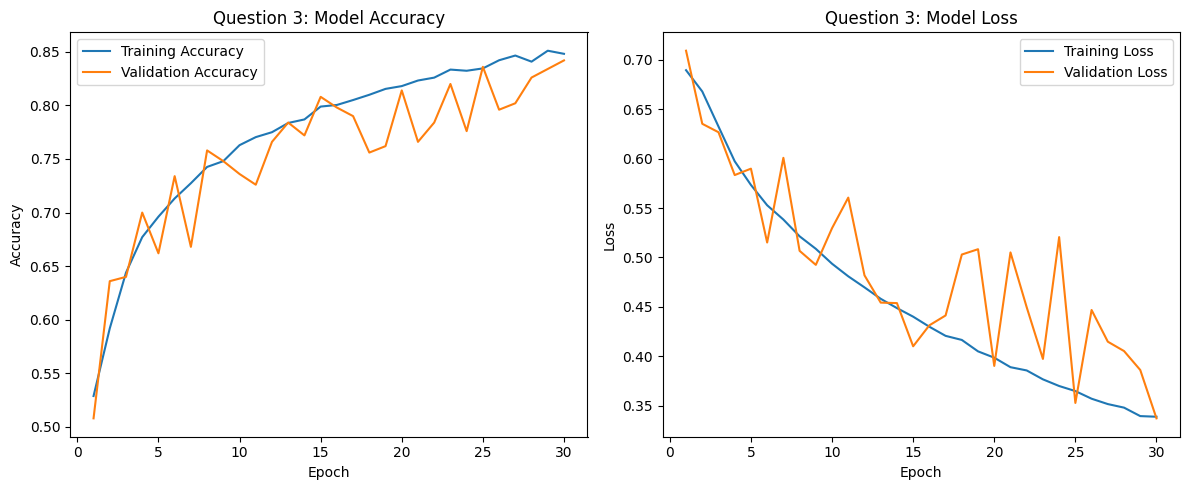

All Question 3 results saved successfully!
Location: /content/drive/MyDrive/BA64061_Assignment2


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
from google.colab import drive

# Connect Google Drive if necessary
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

# Assignment folder
save_dir = Path("/content/drive/MyDrive/BA64061_Assignment2")
save_dir.mkdir(parents=True, exist_ok=True)

# 1. Save training history for Question 3
history_df = pd.DataFrame(history_q3large.history)
history_df.insert(0, "Epoch", range(1, len(history_df) + 1))

history_df.to_csv(
    save_dir / "question3_training_history.csv",
    index=False
)

# 2. Save the comparison of Questions 1–3
results_df = pd.DataFrame([
    {
        "Experiment": "Question 1",
        "Training Images": 1000,
        "Best Epoch": 28,
        "Validation Accuracy": 0.6460,
        "Validation Loss": 0.6236,
        "Test Accuracy": 0.6860,
        "Test Loss": 0.6196
    },
    {
        "Experiment": "Question 2",
        "Training Images": 2000,
        "Best Epoch": 30,
        "Validation Accuracy": 0.6980,
        "Validation Loss": 0.5509,
        "Test Accuracy": 0.7020,
        "Test Loss": 0.5467
    },
    {
        "Experiment": "Question 3",
        "Training Images": 9996,
        "Best Epoch": 30,
        "Validation Accuracy": 0.8420,
        "Validation Loss": 0.3373,
        "Test Accuracy": 0.8300,
        "Test Loss": 0.371362
    }
])

results_df.to_csv(
    save_dir / "cnn_comparison_results.csv",
    index=False
)

# 3. Save the trained CNN model
model_q3large.save(
    str(save_dir / "question3_large_final.keras")
)

# 4. Save training curves
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(
    history_df["Epoch"],
    history_df["accuracy"],
    label="Training Accuracy"
)
axes[0].plot(
    history_df["Epoch"],
    history_df["val_accuracy"],
    label="Validation Accuracy"
)
axes[0].set_title("Question 3: Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(
    history_df["Epoch"],
    history_df["loss"],
    label="Training Loss"
)
axes[1].plot(
    history_df["Epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)
axes[1].set_title("Question 3: Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig(
    save_dir / "question3_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("All Question 3 results saved successfully!")
print("Location:", save_dir)

Q4:

Repeat Steps 1-3, but now using a pretrained network. The sample sizes you use in Steps 2 and 3 for the pretrained network may be the same or different from those using the network where you trained from scratch. Again, use any and all optimization techniques to get best performance.

For this section, I am using the pretrained VGG16 experiments from the text book.

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

conv_base = keras.applications.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(180, 180, 3)
)

# Freeze pretrained convolutional layers
conv_base.trainable = False

conv_base.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_13 (InputLayer)     │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 180, 180, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 180, 180, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 90, 90, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 90, 90, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 90, 90, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 45, 45, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 45, 45, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 45, 45, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 45, 45, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 22, 22, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 22, 22, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 22, 22, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 22, 22, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 11, 11, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 11, 11, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 11, 11, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 11, 11, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 5, 5, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

Build the classifier

In [ ]:
keras.utils.set_random_seed(123)

inputs = keras.Input(shape=(180, 180, 3))

x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.1)(x)
x = layers.RandomZoom(0.2)(x)

# VGG16 requires its own preprocessing
x = keras.applications.vgg16.preprocess_input(x)

# Frozen pretrained convolutional base
x = conv_base(x, training=False)

x = layers.Flatten()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model_vgg16_q4a = keras.Model(inputs, outputs)

model_vgg16_q4a.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_vgg16_q4a.summary()

Model: "functional_14"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_15      │ (None, 180, 180,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip_8       │ (None, 180, 180,  │          0 │ input_layer_15[0… │
│ (RandomFlip)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation_8   │ (None, 180, 180,  │          0 │ random_flip_8[0]… │
│ (RandomRotation)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_zoom_8       │ (None, 180, 180,  │          0 │ random_rotation_… │
│ (RandomZoom)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_3          │ (None, 180, 180)  │          0 │ random_zoom_8[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_4          │ (None, 180, 180)  │          0 │ random_zoom_8[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_5          │ (None, 180, 180)  │          0 │ random_zoom_8[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_1 (Stack)     │ (None, 180, 180,  │          0 │ get_item_3[0][0], │
│                     │ 3)                │            │ get_item_4[0][0], │
│                     │                   │            │ get_item_5[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 180, 180,  │          0 │ stack_1[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 5, 5, 512) │ 14,714,688 │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_7 (Flatten) │ (None, 12800)     │          0 │ vgg16[1][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 256)       │  3,277,056 │ flatten_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 256)       │          0 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 1)         │        257 │ dropout_7[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 17,992,001 (68.63 MB)

 Trainable params: 3,277,313 (12.50 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Train the first pretrained model

In [ ]:
callbacks_vgg16_q4a = [
    keras.callbacks.ModelCheckpoint(
        "/content/drive/MyDrive/BA64061_Assignment2/vgg16_q4a.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )
]

history_vgg16_q4a = model_vgg16_q4a.fit(
    train_dataset,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks_vgg16_q4a
)

Epoch 1/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 9s 219ms/step - accuracy: 0.8300 - loss: 2.1155 - val_accuracy: 0.9580 - val_loss: 0.4830
Epoch 2/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 182ms/step - accuracy: 0.9180 - loss: 0.8812 - val_accuracy: 0.9660 - val_loss: 0.4718
Epoch 3/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 183ms/step - accuracy: 0.9300 - loss: 0.6455 - val_accuracy: 0.9600 - val_loss: 0.4460
Epoch 4/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 179ms/step - accuracy: 0.9610 - loss: 0.2732 - val_accuracy: 0.9660 - val_loss: 0.3332
Epoch 5/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 159ms/step - accuracy: 0.9580 - loss: 0.3001 - val_accuracy: 0.9660 - val_loss: 0.3625
Epoch 6/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 201ms/step - accuracy: 0.9730 - loss: 0.2417 - val_accuracy: 0.9620 - val_loss: 0.2771
Epoch 7/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 154ms/step - accuracy: 0.9670 - loss: 0.1931 - val_accuracy: 0.9680 - val_loss: 0.4083
Epoch 8/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 153ms/step - accuracy: 0.9730 - loss: 0.2085 - val_accuracy: 0.

Examine the validation performance

In [ ]:
import numpy as np

best_epoch = np.argmin(history_vgg16_q4a.history["val_loss"])

print("VGG16 - 1,000 Training Images")
print(f"Best Epoch: {best_epoch + 1}")
print(
    f"Validation Accuracy: "
    f"{history_vgg16_q4a.history['val_accuracy'][best_epoch]:.4f}"
)
print(
    f"Validation Loss: "
    f"{history_vgg16_q4a.history['val_loss'][best_epoch]:.4f}"
)

VGG16 - 1,000 Training Images
Best Epoch: 10
Validation Accuracy: 0.9680
Validation Loss: 0.2395


In the first pretrained VGG16 experiment, results show a 96.8% validation accuracy using only 1000 training images. That's a large improvement over the CNN trained from scratch.

Save the results and evaluate the test set

In [ ]:
# Question 4A: Evaluate pretrained VGG16

test_loss_vgg16_q4a, test_accuracy_vgg16_q4a = (
    model_vgg16_q4a.evaluate(test_dataset)
)

print("VGG16 - 1,000 Training Images")
print(f"Test Accuracy: {test_accuracy_vgg16_q4a:.4f}")
print(f"Test Loss: {test_loss_vgg16_q4a:.4f}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step - accuracy: 0.9680 - loss: 0.2339
VGG16 - 1,000 Training Images
Test Accuracy: 0.9680
Test Loss: 0.2339


Save the training history and results

In [ ]:
import pandas as pd
from pathlib import Path

save_dir = Path("/content/drive/MyDrive/BA64061_Assignment2")
save_dir.mkdir(parents=True, exist_ok=True)

# Save training history
history_df = pd.DataFrame(history_vgg16_q4a.history)
history_df.insert(0, "Epoch", range(1, len(history_df) + 1))

history_df.to_csv(
    save_dir / "vgg16_q4a_training_history.csv",
    index=False
)

# Save evaluation results
results_vgg16_q4a = pd.DataFrame([{
    "Experiment": "Question 4A",
    "Network": "Pretrained VGG16",
    "Training Images": 1000,
    "Best Epoch": 10,
    "Validation Accuracy": 0.9680,
    "Validation Loss": 0.2395,
    "Test Accuracy": test_accuracy_vgg16_q4a,
    "Test Loss": test_loss_vgg16_q4a
}])

results_vgg16_q4a.to_csv(
    save_dir / "vgg16_q4a_results.csv",
    index=False
)

print("VGG16 Question 4A results saved successfully.")

VGG16 Question 4A results saved successfully.


Using the same pretrained VGG16 with 2000 training images

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(123)

# Load a fresh pretrained VGG16 base
conv_base_q4b = keras.applications.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(180, 180, 3)
)

conv_base_q4b.trainable = False

augmentation_q4b = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2)
])

inputs = keras.Input(shape=(180, 180, 3))

x = augmentation_q4b(inputs)
x = keras.applications.vgg16.preprocess_input(x)

x = conv_base_q4b(x, training=False)

x = layers.Flatten()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model_vgg16_q4b = keras.Model(inputs, outputs)

model_vgg16_q4b.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_vgg16_q4b.summary()

Model: "functional_16"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_17      │ (None, 180, 180,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_7        │ (None, 180, 180,  │          0 │ input_layer_17[0… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_6          │ (None, 180, 180)  │          0 │ sequential_7[0][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_7          │ (None, 180, 180)  │          0 │ sequential_7[0][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_8          │ (None, 180, 180)  │          0 │ sequential_7[0][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_2 (Stack)     │ (None, 180, 180,  │          0 │ get_item_6[0][0], │
│                     │ 3)                │            │ get_item_7[0][0], │
│                     │                   │            │ get_item_8[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 180, 180,  │          0 │ stack_2[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 5, 5, 512) │ 14,714,688 │ add_2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_8 (Flatten) │ (None, 12800)     │          0 │ vgg16[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 256)       │  3,277,056 │ flatten_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 256)       │          0 │ dense_11[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 1)         │        257 │ dropout_8[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 17,992,001 (68.63 MB)

 Trainable params: 3,277,313 (12.50 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

train using 2000 images

In [ ]:
callbacks_vgg16_q4b = [
    keras.callbacks.ModelCheckpoint(
        "/content/drive/MyDrive/BA64061_Assignment2/vgg16_q4b.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )
]

history_vgg16_q4b = model_vgg16_q4b.fit(
    train_dataset_q2,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks_vgg16_q4b
)

Epoch 1/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 169ms/step - accuracy: 0.8670 - loss: 1.6991 - val_accuracy: 0.9600 - val_loss: 0.4479
Epoch 2/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 150ms/step - accuracy: 0.9240 - loss: 0.8317 - val_accuracy: 0.9660 - val_loss: 0.3349
Epoch 3/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 144ms/step - accuracy: 0.9345 - loss: 0.5742 - val_accuracy: 0.9660 - val_loss: 0.2711
Epoch 4/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 139ms/step - accuracy: 0.9485 - loss: 0.3995 - val_accuracy: 0.9780 - val_loss: 0.2020
Epoch 5/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 127ms/step - accuracy: 0.9550 - loss: 0.3200 - val_accuracy: 0.9740 - val_loss: 0.2429
Epoch 6/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 135ms/step - accuracy: 0.9655 - loss: 0.2111 - val_accuracy: 0.9780 - val_loss: 0.1790
Epoch 7/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 10s 132ms/step - accuracy: 0.9660 - loss: 0.1806 - val_accuracy: 0.9800 - val_loss: 0.1522
Epoch 8/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 128ms/step - accuracy: 0.9730 - loss: 0.1553 - val_accuracy: 

Examine validation results

In [ ]:
import numpy as np

best_epoch_q4b = np.argmin(
    history_vgg16_q4b.history["val_loss"]
)

print("VGG16 - 2,000 Training Images")
print(f"Best Epoch: {best_epoch_q4b + 1}")

print(
    "Validation Accuracy:",
    f"{history_vgg16_q4b.history['val_accuracy'][best_epoch_q4b]:.4f}"
)

print(
    "Validation Loss:",
    f"{history_vgg16_q4b.history['val_loss'][best_epoch_q4b]:.4f}"
)

VGG16 - 2,000 Training Images
Best Epoch: 7
Validation Accuracy: 0.9800
Validation Loss: 0.1522


The second pretrained VGG16 experiment achieved 98% validation accuracy using 2000 training images.

In [ ]:
# Evaluate pretrained VGG16 using 2,000 training images

test_loss_vgg16_q4b, test_accuracy_vgg16_q4b = (
    model_vgg16_q4b.evaluate(test_dataset)
)

print("VGG16 - 2,000 Training Images")
print(f"Test Accuracy: {test_accuracy_vgg16_q4b:.4f}")
print(f"Test Loss: {test_loss_vgg16_q4b:.4f}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 102ms/step - accuracy: 0.9800 - loss: 0.2343
VGG16 - 2,000 Training Images
Test Accuracy: 0.9800
Test Loss: 0.2343


This finding demonstrates that the model correctly classified 490 out of 500 test images.

Although the accuracy improved, the test loss of 0.2343 was slightly higher than the previous finding 0.2339. That means improved classification accuracy did not necessarily produce better probability estimates overall.

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

save_dir = Path("/content/drive/MyDrive/BA64061_Assignment2")

# Save complete training history
history_q4b_df = pd.DataFrame(history_vgg16_q4b.history)
history_q4b_df.insert(
    0, "Epoch",
    range(1, len(history_q4b_df) + 1)
)

history_q4b_df.to_csv(
    save_dir / "vgg16_q4b_training_history.csv",
    index=False
)

# Save results
best_epoch_q4b = np.argmin(
    history_vgg16_q4b.history["val_loss"]
)

results_q4b = pd.DataFrame([{
    "Experiment": "Question 4B",
    "Model": "Pretrained VGG16",
    "Training Images": 2000,
    "Best Epoch": best_epoch_q4b + 1,
    "Validation Accuracy": history_vgg16_q4b.history[
        "val_accuracy"
    ][best_epoch_q4b],
    "Validation Loss": history_vgg16_q4b.history[
        "val_loss"
    ][best_epoch_q4b],
    "Test Accuracy": test_accuracy_vgg16_q4b,
    "Test Loss": test_loss_vgg16_q4b
}])

results_q4b.to_csv(
    save_dir / "vgg16_q4b_results.csv",
    index=False
)

print("Question 4B results saved successfully.")

Question 4B results saved successfully.


The next section will repeat the VGG16 experiment using the larger training dataset with 9,996 images.

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(123)

conv_base_q4c = keras.applications.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(180, 180, 3)
)

conv_base_q4c.trainable = False

augmentation_q4c = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2)
])

inputs = keras.Input(shape=(180, 180, 3))

x = augmentation_q4c(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base_q4c(x, training=False)

x = layers.Flatten()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model_vgg16_q4c = keras.Model(inputs, outputs)

model_vgg16_q4c.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_vgg16_q4c.summary()

Model: "functional_18"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_20      │ (None, 180, 180,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_8        │ (None, 180, 180,  │          0 │ input_layer_20[0… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_9          │ (None, 180, 180)  │          0 │ sequential_8[0][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_10         │ (None, 180, 180)  │          0 │ sequential_8[0][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_11         │ (None, 180, 180)  │          0 │ sequential_8[0][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_3 (Stack)     │ (None, 180, 180,  │          0 │ get_item_9[0][0], │
│                     │ 3)                │            │ get_item_10[0][0… │
│                     │                   │            │ get_item_11[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 180, 180,  │          0 │ stack_3[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 5, 5, 512) │ 14,714,688 │ add_3[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_9 (Flatten) │ (None, 12800)     │          0 │ vgg16[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 256)       │  3,277,056 │ flatten_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 256)       │          0 │ dense_13[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, 1)         │        257 │ dropout_9[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 17,992,001 (68.63 MB)

 Trainable params: 3,277,313 (12.50 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Train using the larger dataset

In [ ]:
callbacks_vgg16_q4c = [
    keras.callbacks.ModelCheckpoint(
        "/content/drive/MyDrive/BA64061_Assignment2/vgg16_q4c.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )
]

history_vgg16_q4c = model_vgg16_q4c.fit(
    train_dataset_q3large,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks_vgg16_q4c
)

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 40s 120ms/step - accuracy: 0.9157 - loss: 0.8939 - val_accuracy: 0.9720 - val_loss: 0.3005
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - accuracy: 0.9514 - loss: 0.3038 - val_accuracy: 0.9740 - val_loss: 0.1404
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 35s 111ms/step - accuracy: 0.9596 - loss: 0.1980 - val_accuracy: 0.9740 - val_loss: 0.1144
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 35s 110ms/step - accuracy: 0.9617 - loss: 0.1644 - val_accuracy: 0.9840 - val_loss: 0.1133
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - accuracy: 0.9678 - loss: 0.1537 - val_accuracy: 0.9820 - val_loss: 0.1216
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - accuracy: 0.9711 - loss: 0.1321 - val_accuracy: 0.9780 - val_loss: 0.1408
Epoch 7/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 34s 110ms/step - accuracy: 0.9728 - loss: 0.1173 - val_accuracy: 0.9800 - val_loss: 0.1080
Epoch 8/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - accuracy: 0.9765 - loss: 0

Evaluate the results

In [ ]:
import numpy as np

best_epoch_q4c = np.argmin(
    history_vgg16_q4c.history["val_loss"]
)

print("VGG16 - 9,996 Training Images")
print(f"Best Epoch: {best_epoch_q4c + 1}")
print(
    "Validation Accuracy:",
    f"{history_vgg16_q4c.history['val_accuracy'][best_epoch_q4c]:.4f}"
)
print(
    "Validation Loss:",
    f"{history_vgg16_q4c.history['val_loss'][best_epoch_q4c]:.4f}"
)

VGG16 - 9,996 Training Images
Best Epoch: 12
Validation Accuracy: 0.9860
Validation Loss: 0.0953


The final pretrained VGG16 experiment achieved 98.6% validation accuracy using 9,996 training images. That's the highest validation accuracy so far.

These reults suggest that increasing sample size still benefits a pretrained network, but the improvement in accuracy becomes smaller as performance approaches 100%.

The model achieved 98.6% test accuracy, correctly identifying 493 of 500 test images.

In [ ]:
# Evaluate pretrained VGG16 trained on 9,996 images

test_loss_vgg16_q4c, test_accuracy_vgg16_q4c = (
    model_vgg16_q4c.evaluate(test_dataset)
)

print("VGG16 - 9,996 Training Images")
print(f"Test Accuracy: {test_accuracy_vgg16_q4c:.4f}")
print(f"Test Loss: {test_loss_vgg16_q4c:.4f}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.9860 - loss: 0.1072
VGG16 - 9,996 Training Images
Test Accuracy: 0.9860
Test Loss: 0.1072


In [ ]:
import pandas as pd
from pathlib import Path

save_dir = Path("/content/drive/MyDrive/BA64061_Assignment2")
save_dir.mkdir(parents=True, exist_ok=True)

# Save training history
history_q4c_df = pd.DataFrame(history_vgg16_q4c.history)
history_q4c_df.insert(
    0,
    "Epoch",
    range(1, len(history_q4c_df) + 1)
)

history_q4c_df.to_csv(
    save_dir / "vgg16_q4c_training_history.csv",
    index=False
)

# Save experiment results
results_q4c = pd.DataFrame([{
    "Experiment": "Question 4C",
    "Model": "Pretrained VGG16",
    "Training Images": 9996,
    "Best Epoch": best_epoch_q4c + 1,
    "Validation Accuracy": 0.9860,
    "Validation Loss": 0.0953,
    "Test Accuracy": test_accuracy_vgg16_q4c,
    "Test Loss": test_loss_vgg16_q4c
}])

results_q4c.to_csv(
    save_dir / "vgg16_q4c_results.csv",
    index=False
)

print("Question 4C results saved successfully.")

Question 4C results saved successfully.


These results illustrate two important findings:
1. Training sample size matters more for a CNN trained from scratch. Accuracy increased by 14.4 percentage points between 1,000 and 9,996 training images.
2. Transfer learning substantially improves performance with limited data. The pretrained VGG16 model achieved 96.80% accuracy with just 1,000 images, exceeding the scratch CNN's 83.00% result with nearly 10,000 images.

Create the final comparison table

In [ ]:
import pandas as pd
from pathlib import Path

# Assignment folder in Google Drive
save_dir = Path("/content/drive/MyDrive/BA64061_Assignment2")
save_dir.mkdir(parents=True, exist_ok=True)

# Results from all six experiments
results = pd.DataFrame([
    ["CNN from scratch", 1000, 28, 0.6460, 0.6236, 0.6860, 0.6196],
    ["CNN from scratch", 2000, 30, 0.6980, 0.5509, 0.7020, 0.5467],
    ["CNN from scratch", 9996, 30, 0.8420, 0.3373, 0.8300, 0.371362],
    ["Pretrained VGG16", 1000, 10, 0.9680, 0.2395, 0.9680, 0.2339],
    ["Pretrained VGG16", 2000, 7, 0.9800, 0.1522, 0.9800, 0.2343],
    ["Pretrained VGG16", 9996, 12, 0.9860, 0.0953, 0.9860, 0.1072]
], columns=[
    "Model",
    "Training Images",
    "Best Epoch",
    "Validation Accuracy",
    "Validation Loss",
    "Test Accuracy",
    "Test Loss"
])

# Save complete numerical results
results.to_csv(
    save_dir / "final_model_comparison.csv",
    index=False
)

# Create a formatted display table
display_results = results.copy()

display_results["Validation Accuracy"] = (
    display_results["Validation Accuracy"] * 100
).map("{:.2f}%".format)

display_results["Test Accuracy"] = (
    display_results["Test Accuracy"] * 100
).map("{:.2f}%".format)

display_results["Validation Loss"] = (
    display_results["Validation Loss"].map("{:.4f}".format)
)

display_results["Test Loss"] = (
    display_results["Test Loss"].map("{:.4f}".format)
)

display(display_results)

print("Final comparison table saved!")

,Model,Training Images,Best Epoch,Validation Accuracy,Validation Loss,Test Accuracy,Test Loss
0,CNN from scratch,1000,28,64.60%,0.6236,68.60%,0.6196
1,CNN from scratch,2000,30,69.80%,0.5509,70.20%,0.5467
2,CNN from scratch,9996,30,84.20%,0.3373,83.00%,0.3714
3,Pretrained VGG16,1000,10,96.80%,0.2395,96.80%,0.2339
4,Pretrained VGG16,2000,7,98.00%,0.1522,98.00%,0.2343
5,Pretrained VGG16,9996,12,98.60%,0.0953,98.60%,0.1072


Final comparison table saved!


Create the comparison graph

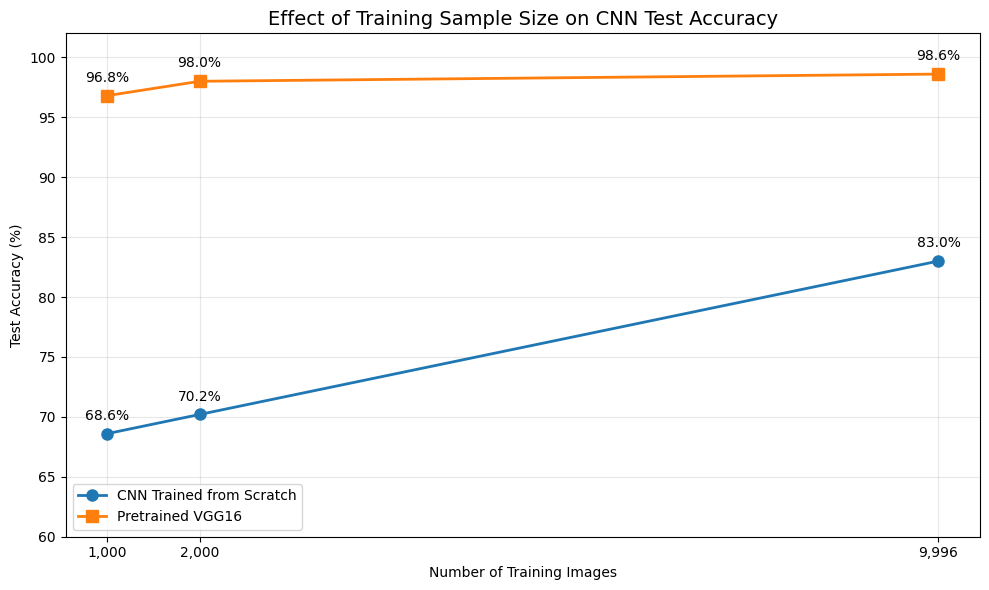

Comparison graph saved!


In [ ]:
import matplotlib.pyplot as plt

# Separate the two model types
scratch = results[
    results["Model"] == "CNN from scratch"
].sort_values("Training Images")

pretrained = results[
    results["Model"] == "Pretrained VGG16"
].sort_values("Training Images")

plt.figure(figsize=(10, 6))

# CNN trained from scratch
plt.plot(
    scratch["Training Images"],
    scratch["Test Accuracy"] * 100,
    marker="o",
    linewidth=2,
    markersize=8,
    label="CNN Trained from Scratch"
)

# Pretrained VGG16
plt.plot(
    pretrained["Training Images"],
    pretrained["Test Accuracy"] * 100,
    marker="s",
    linewidth=2,
    markersize=8,
    label="Pretrained VGG16"
)

plt.title(
    "Effect of Training Sample Size on CNN Test Accuracy",
    fontsize=14
)
plt.xlabel("Number of Training Images")
plt.ylabel("Test Accuracy (%)")

plt.xticks([1000, 2000, 9996], ["1,000", "2,000", "9,996"])
plt.ylim(60, 102)

plt.grid(True, alpha=0.3)
plt.legend()

# Display accuracy values beside the points
for df in [scratch, pretrained]:
    for _, row in df.iterrows():
        plt.annotate(
            f"{row['Test Accuracy'] * 100:.1f}%",
            (
                row["Training Images"],
                row["Test Accuracy"] * 100
            ),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center"
        )

plt.tight_layout()

plt.savefig(
    save_dir / "final_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Comparison graph saved!")

Create a validation accuracy comparison graph

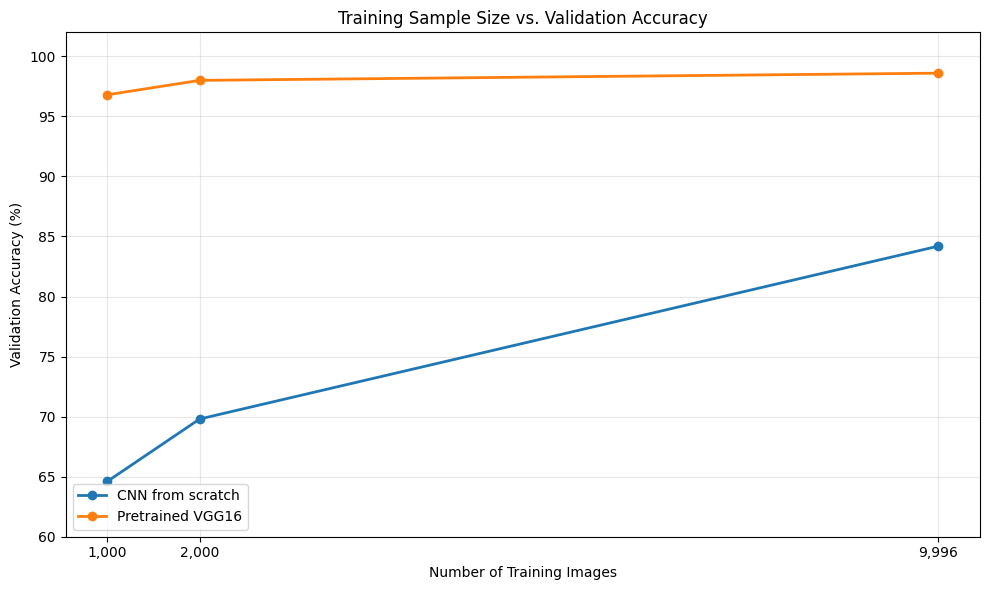

Validation comparison graph saved!


In [ ]:
plt.figure(figsize=(10, 6))

for model_name, group in results.groupby("Model"):
    group = group.sort_values("Training Images")

    plt.plot(
        group["Training Images"],
        group["Validation Accuracy"] * 100,
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.title("Training Sample Size vs. Validation Accuracy")
plt.xlabel("Number of Training Images")
plt.ylabel("Validation Accuracy (%)")

plt.xticks([1000, 2000, 9996], ["1,000", "2,000", "9,996"])
plt.ylim(60, 102)

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    save_dir / "final_validation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Validation comparison graph saved!")

Save a formatted table as an image

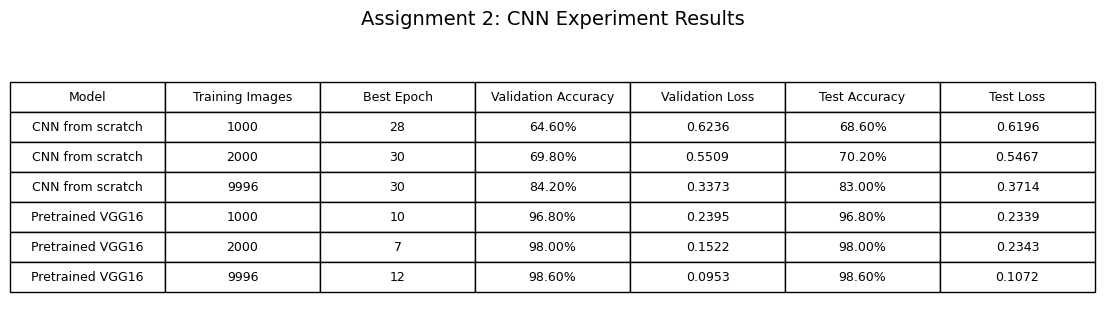

Formatted comparison table saved!


In [ ]:
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.axis("off")

table = ax.table(
    cellText=display_results.values,
    colLabels=display_results.columns,
    loc="center",
    cellLoc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.8)

plt.title(
    "Assignment 2: CNN Experiment Results",
    fontsize=14,
    pad=20
)

plt.savefig(
    save_dir / "final_comparison_table.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Formatted comparison table saved!")